# What if breathing is only helpful on the weekend?

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


INFERENCE MODEL SPECIFICATIONS

WITHOUT COVARIATE
  Name: Without Covariate
  Mean shape: (2,)
  V shape: (2, 2)
  V diagonal: 100.00
  Alpha: 1.00
  Beta: 1.00
  Prior means: [0. 0.]

WITH COVARIATE
  Name: With Covariate
  Mean shape: (3,)
  V shape: (3, 3)
  V diagonal: 100.00
  Alpha: 1.00
  Beta: 1.00
  Covariate names: ['L']
  Prior means: [0. 0. 0.]

Running SCM Behavioral Compensation Model Simulation...


100%|██████████| 200/200 [00:03<00:00, 54.26it/s]


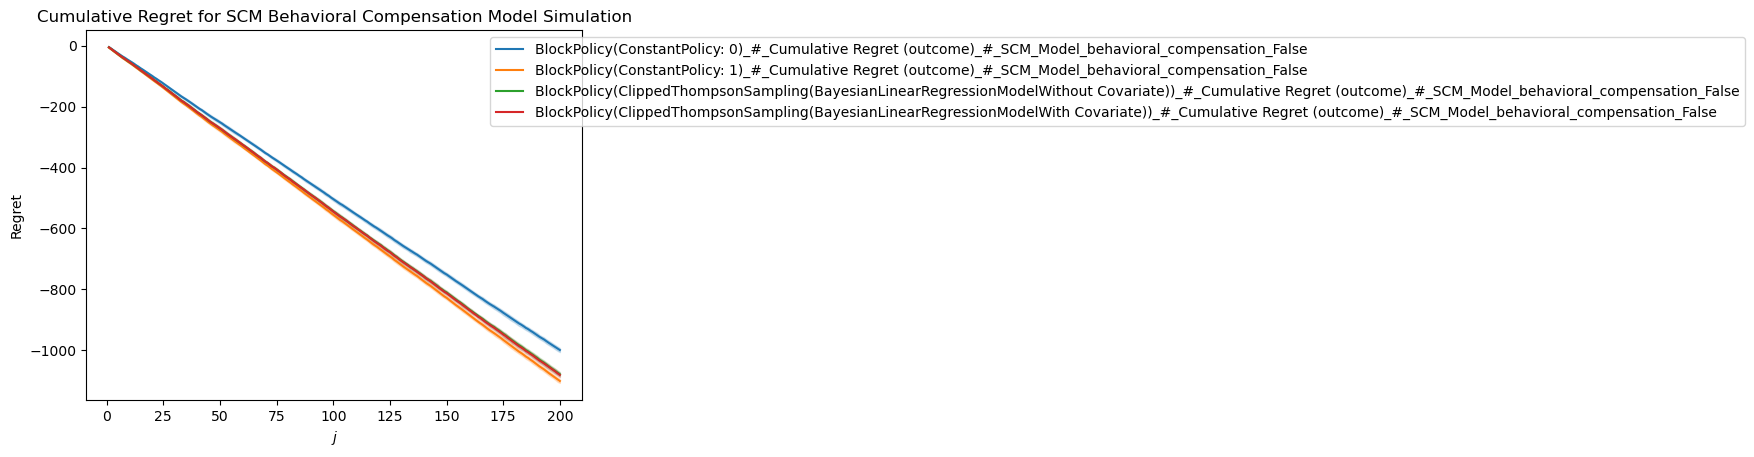

In [12]:
import numpy
import torch
import seaborn
from adaptive_nof1 import *
from adaptive_nof1.policies import *
from adaptive_nof1.helpers import *
from adaptive_nof1.inference import *
from adaptive_nof1.metrics import *
from adaptive_nof1.models import *
from matplotlib import pyplot as plt
from adaptive_nof1.patient_explorer import show_patient_explorer
import pandas

# Import the new SklearnSimulationModel
from adaptive_nof1.models.sklearn_simulation_model import SklearnSimulationModel
from adaptive_nof1.basic_types import Observation


# Initial parameters for simulation
block_length = 1
length = 200 * block_length
number_of_actions = 2
number_of_patients = 10

# Define Structural Causal Model (SCM) similar to scm_models_01
class StructuralCausalModel(Model):
    def __init__(self, patient_id, starting_context, context_function, outcome_function, name, context_variance=1.0, outcome_variance=1.0):
        self.rng = numpy.random.default_rng(patient_id)
        self.starting_context = starting_context
        self.context_function = context_function
        self.outcome_function = outcome_function
        self.name = name
        self.patient_id = patient_id
        self.context_variance = context_variance
        self.outcome_variance = outcome_variance

    def generate_context(self, history):
        if len(history.observations) == 0:
            return {"L": self.context_function(k=0), **self.starting_context}
        
        last_observation = history.observations[-1]
        last_context = last_observation.context
        Y_k_minus_1 = last_observation.outcome["outcome"]
        L_k_minus_1 = last_context["L"]
        A_k_minus_1 = last_observation.treatment["treatment"]
        return {"L": self.context_function(Y_k_minus_1=Y_k_minus_1, L_k_minus_1=L_k_minus_1, A_k_minus_1=A_k_minus_1, k=len(history.observations)) + self.rng.normal(0, self.context_variance), "Y_k_minus_1": Y_k_minus_1}

    @property
    def additional_config(self):
        return {}

    @property
    def number_of_interventions(self):
        return 2

    def observe_outcome(self, action, context):
        outcome = self.outcome_function(action=action, L=context["L"], Y_k_minus_1=context["Y_k_minus_1"]) + self.rng.normal(0, self.outcome_variance)
        return {"outcome": outcome}

    def __str__(self):
        return f"SCM_Model_{self.name}"

# Behavioral Compensation Model: Randomly drawn covariate each day, modified by action
def create_behavioral_compensation_scenario():
    """
    Create scenario with behavioral compensation where covariate is influenced by action.
    
    Well-being model: W = β₀ + β₁E + γL + ε
    where:
    - E = exercise (treatment: 0 or 1)
    - L = covariate influenced by previous action (e.g., stress level, fatigue)
    - β₀ = 5.0 (baseline well-being)
    - β₁ = 2.0 (exercise helps directly)
    - γ = -1.0 (high L (stress/fatigue) reduces well-being)
    
    Covariate dynamics:
    - L = random noise + bonus if previous action was 1 (exercise creates fatigue/stress)
    """
    
    # Parameters
    beta_0 = 5.0
    beta_1 = 2.0  # Exercise helps directly
    gamma = -1.0  # Stress/fatigue reduces well-being
    action_effect = 1.5  # Exercise increases stress/fatigue by this amount
    
    def context_function_factory(patient_id):
        """Create a context function with patient-specific RNG for random daily covariates."""
        rng = numpy.random.default_rng(patient_id)
        
        def context_function(Y_k_minus_1=None, L_k_minus_1=None, A_k_minus_1=None, k=0):
            # Draw random covariate each day
            L_random = float(rng.normal(0, 1))
            
            # If previous action was 1 (exercise), increase stress/fatigue
            L_effect = 0.0
            if A_k_minus_1 is not None and A_k_minus_1 == 1:
                L_effect = action_effect
            
            # Total covariate: random component + action effect
            L = L_random + L_effect
            return L
        
        return context_function
    
    # Outcome function: behavioral compensation model
    def outcome_function(action, L, Y_k_minus_1):
        E = float(action["treatment"])  # Exercise: 0 or 1
        # W = β₀ + β₁E + γL
        # Exercise helps (+β₁) but also increases stress/fatigue (+action_effect on L)
        # which then reduces well-being (γ < 0)
        well_being = beta_0 + beta_1 * E + gamma * L
        return well_being
    
    starting_context = {"Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0}
    
    return context_function_factory, outcome_function, starting_context


# Create inference models dynamically
def create_inference_model(include_covariate=True):
    """
    Create a BayesianLinearRegressionModel.
    
    Parameters:
    -----------
    include_covariate : bool
        If True, include covariate L as a continuous predictor
    
    Returns:
    --------
    BayesianLinearRegressionModel
    """
    # Use weakly informative priors
    WEAKLY_INFORMATIVE = {
    'cov_diag': 100.0,  # Large covariance = high uncertainty
    'alpha': 1.0,  # Vague prior on variance
    'beta': 1.0,  # Vague prior on variance
    }
    prior_spec = WEAKLY_INFORMATIVE
    prior_means_treatment = numpy.array([0.0, 0.0])  # Centered at zero
    
    # Build model name
    model_name = "With Covariate" if include_covariate else "Without Covariate"
    
    if include_covariate:
        # Design matrix structure: Treatment (2) + Covariate (continuous)
        mean = numpy.array([0.0, 0.0, 0.0])  # [treatment_0, treatment_1, covariate]
        v = numpy.eye(3) * prior_spec['cov_diag']
        
        return BayesianLinearRegressionModel(
            mean=mean,
            v=v,
            alpha=prior_spec['alpha'],
            beta=prior_spec['beta'],
            covariate_names=["L"],
            name=model_name
        )
    else:
        # Only treatment (2 coefficients)
        mean = prior_means_treatment
        v = numpy.eye(2) * prior_spec['cov_diag']
        
        return BayesianLinearRegressionModel(
            mean=mean,
            v=v,
            alpha=prior_spec['alpha'],
            beta=prior_spec['beta'],
            covariate_names=[],
            name=model_name
        )

# Create 2 inference models
inference_models = {
    'without_covariate': create_inference_model(include_covariate=False),
    'with_covariate': create_inference_model(include_covariate=True),
}

# Print model specifications
print("=" * 80)
print("INFERENCE MODEL SPECIFICATIONS")
print("=" * 80)
for key, model in inference_models.items():
    print(f"\n{key.upper().replace('_', ' ')}")
    print(f"  Name: {model.name}")
    print(f"  Mean shape: {model.mean.shape}")
    print(f"  V shape: {model.v.shape}")
    print(f"  V diagonal: {numpy.diag(model.v)[0]:.2f}")
    print(f"  Alpha: {model.alpha:.2f}")
    print(f"  Beta: {model.beta:.2f}")
    if hasattr(model, 'covariate_names') and model.covariate_names:
        print(f"  Covariate names: {model.covariate_names}")
    print(f"  Prior means: {model.mean}")

# Create scenarios: SCM behavioral compensation model with action-dependent covariate
scm_scenarios = {}

# Behavioral compensation model scenario
context_func_factory, outcome_func, starting_context = create_behavioral_compensation_scenario()
scm_scenarios['scm_behavioral_compensation'] = {
    'context_function_factory': context_func_factory,
    'outcome_function': outcome_func,
    'starting_context': starting_context,
    'generator': lambda pid, ctx=starting_context, cff=context_func_factory, of=outcome_func: StructuralCausalModel(
        pid, 
        ctx,
        cff(pid),  # Create patient-specific context function with its own RNG
        of,
        context_variance=0.0,
        outcome_variance=0.3,  # Small noise for realism
        name='behavioral_compensation',
    ),
    'description': 'Behavioral Compensation: Exercise increases stress but also improves well-being'
}

# Define policies with 2 inference models
policies = [
    # Constant policies for baseline comparison
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(
            action=0  # Always choose action 0 (no exercise)
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(
            action=1  # Always choose action 1 (always exercise)
        ),
    ),
    
    # Thompson Sampling with 2 inference models
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['without_covariate'],
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['with_covariate'],
        ),
    ),
]

# Generate configurations
study_designs = {
    "n_patients": [number_of_patients],
    "policy": policies,
    "model_from_patient_id": [
        scenario['generator'] for scenario in scm_scenarios.values()
    ],
}

# Generate configuration cross product
configurations = generate_configuration_cross_product(study_designs)

# Run simulation
ENABLE_SIMULATION = True
if ENABLE_SIMULATION:
    print("\nRunning SCM Behavioral Compensation Model Simulation...")
    calculated_series, config_to_simulation_data = simulate_configurations(
        configurations, length
    )
    
    # Optional: Save simulation results
    write_to_disk(
        "data/2025-12-18-scm_behavioral_compensation_simulation.json",
        [calculated_series, config_to_simulation_data],
    )

# Metrics for analysis
metrics = [
    CumulativeRegret(),
]

# Analyze results
if ENABLE_SIMULATION:
    df = SeriesOfSimulationsData.score_data(
        [s["result"] for s in calculated_series],
        metrics,
    )
    
    # Plot results
    ax = SeriesOfSimulationsData.plot_lines(
        [s["result"] for s in calculated_series],
        [CumulativeRegret()],
        legend_position=(0.8, 1.0)
    )
    plt.title('Cumulative Regret for SCM Behavioral Compensation Model Simulation')
    plt.ylabel('Regret')
    plt.show()


In [13]:
plot_allocations_for_calculated_series(
    calculated_series,
)


:Layout
   .HeatMap.I   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.I   :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.II  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.II  :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.III :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.III :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.IV  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.IV  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]

REGRET DISTRIBUTION FOR EACH POLICY

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Covariate))
--------------------------------------------------------------------------------
  Number of simulations: 10
  Mean regret:           -1080.2399
  Median regret:         -1078.0907
  Std deviation:         12.1691
  Min regret:            -1103.6027
  Max regret:            -1063.4052
  25th percentile:       -1090.1516
  75th percentile:       -1069.9249

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWithout Covariate))
--------------------------------------------------------------------------------
  Number of simulations: 10
  Mean regret:           -1078.0399
  Median regret:         -1074.4939
  Std deviation:         12.0517
  Min regret:            -1100.6027
  Max regret:            -1060.4052
  25th percentile:       -1087.9297
  75th percentile:       -1069.1389

BlockPolicy(ConstantPolicy: 0)
-----------------------------------------------

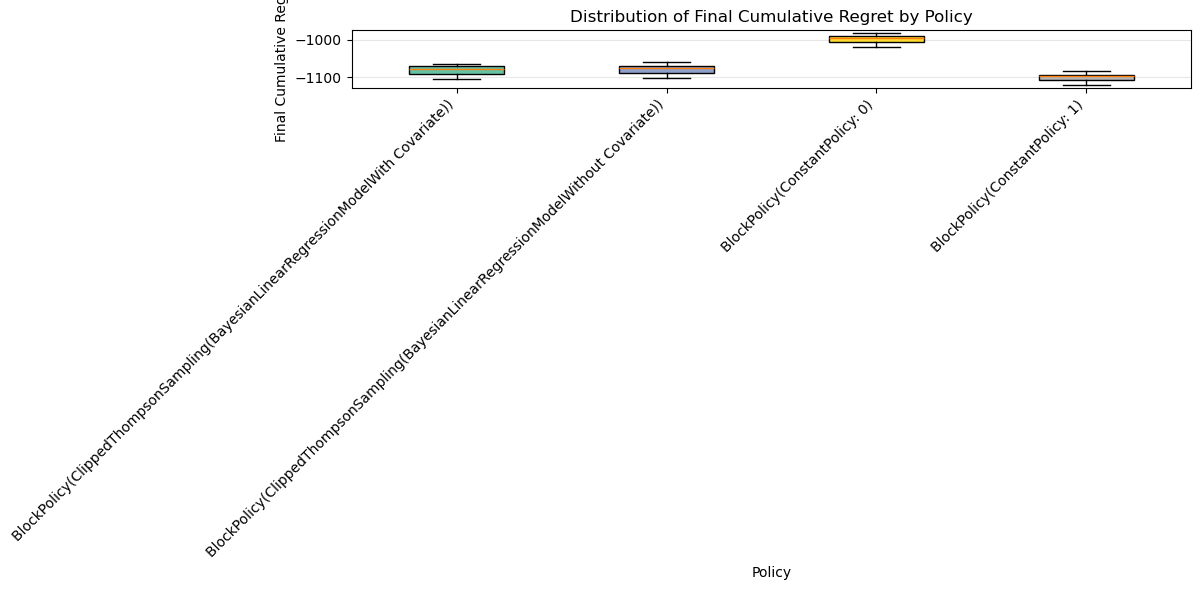

In [17]:
print("=" * 80)
print("REGRET DISTRIBUTION FOR EACH POLICY")
print("=" * 80)

# Use the already calculated df which has regret scores
# Get the final cumulative regret (last time point) for each simulation
policy_regret_dict = {}

# Get the maximum time point (final regret)
if 't' in df.columns and 'score' in df.columns:
    max_t = df['t'].max()
    final_regret_df = df[df['t'] == max_t]
    
    # Group by policy and extract regret scores
    for policy_name in final_regret_df['policy'].unique():
        policy_data = final_regret_df[final_regret_df['policy'] == policy_name]
        # Get the regret scores - score column contains arrays/lists, get the last value
        regret_values = []
        for score_val in policy_data['score'].values:
            if hasattr(score_val, '__iter__') and not isinstance(score_val, str):
                # If it's an array/list, get the last element
                try:
                    regret_values.append(float(score_val[-1]))
                except (IndexError, TypeError):
                    # If indexing fails, try to convert directly
                    try:
                        regret_values.append(float(score_val))
                    except (TypeError, ValueError):
                        pass
            else:
                # If it's a scalar, use it directly
                try:
                    regret_values.append(float(score_val))
                except (TypeError, ValueError):
                    pass
        policy_regret_dict[policy_name] = regret_values
else:
    # Fallback: calculate regret directly from simulations
    regret_metric = CumulativeRegret()
    for series in calculated_series:
        policy_name = str(series["configuration"]["policy"]).split('(')[0]
        regret_values = []
        
        for simulation in series["result"].simulations:
            if len(simulation.history.observations) > 0:
                # Use score_simulations which takes a list
                regret_df = regret_metric.score_simulations([simulation])
                if 'score' in regret_df.columns and len(regret_df) > 0:
                    # score column contains arrays, get the last value from the last row
                    last_score = regret_df['score'].iloc[-1]
                    if hasattr(last_score, '__iter__') and not isinstance(last_score, str):
                        # Get the last element of the array
                        regret_values.append(float(last_score[-1]))
                    else:
                        regret_values.append(float(last_score))
        
        if policy_name not in policy_regret_dict:
            policy_regret_dict[policy_name] = []
        policy_regret_dict[policy_name].extend(regret_values)

# Print statistics for each policy
for policy_name, regret_values in sorted(policy_regret_dict.items()):
    if len(regret_values) > 0:
        regret_array = numpy.array(regret_values)
        print(f"\n{policy_name}")
        print("-" * 80)
        print(f"  Number of simulations: {len(regret_values)}")
        print(f"  Mean regret:           {numpy.mean(regret_array):.4f}")
        print(f"  Median regret:         {numpy.median(regret_array):.4f}")
        print(f"  Std deviation:         {numpy.std(regret_array):.4f}")
        print(f"  Min regret:            {numpy.min(regret_array):.4f}")
        print(f"  Max regret:            {numpy.max(regret_array):.4f}")
        print(f"  25th percentile:       {numpy.percentile(regret_array, 25):.4f}")
        print(f"  75th percentile:       {numpy.percentile(regret_array, 75):.4f}")

# Create a summary DataFrame
summary_data = []
for policy_name, regret_values in sorted(policy_regret_dict.items()):
    if len(regret_values) > 0:
        regret_array = numpy.array(regret_values)
        summary_data.append({
            'Policy': policy_name,
            'Mean': numpy.mean(regret_array),
            'Median': numpy.median(regret_array),
            'Std': numpy.std(regret_array),
            'Min': numpy.min(regret_array),
            'Max': numpy.max(regret_array),
            'Q25': numpy.percentile(regret_array, 25),
            'Q75': numpy.percentile(regret_array, 75),
            'N': len(regret_values)
        })

if summary_data:
    summary_df = pandas.DataFrame(summary_data)
    print("\n" + "=" * 80)
    print("SUMMARY TABLE")
    print("=" * 80)
    print(summary_df.to_string(index=False))
    
    # Plot box plots of regret distributions
    fig, ax = plt.subplots(figsize=(12, 6))
    regret_data = [policy_regret_dict[policy] for policy in sorted(policy_regret_dict.keys())]
    policy_names = sorted(policy_regret_dict.keys())
    
    bp = ax.boxplot(regret_data, patch_artist=True, vert=True)
    ax.set_xticklabels(policy_names, rotation=45, ha='right')
    
    # Color the boxes
    colors = plt.cm.Set2(numpy.linspace(0, 1, len(bp['boxes'])))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    
    ax.set_xlabel('Policy')
    ax.set_ylabel('Final Cumulative Regret')
    ax.set_title('Distribution of Final Cumulative Regret by Policy')
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()


OUTCOME DISTRIBUTION FOR EACH POLICY

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Covariate))
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       5.4012
  Median outcome:     5.4414
  Std deviation:      1.4082
  Min outcome:        0.8416
  Max outcome:        10.3054

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWithout Covariate))
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       5.3902
  Median outcome:     5.4617
  Std deviation:      1.4370
  Min outcome:        0.7002
  Max outcome:        9.5391

BlockPolicy(ConstantPolicy: 0)
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       4.9929
  Median outcome:     4.9919
  Std deviation:      1.0238
  Min outcome:        1.6815
  Max outcome:        8.5760

B

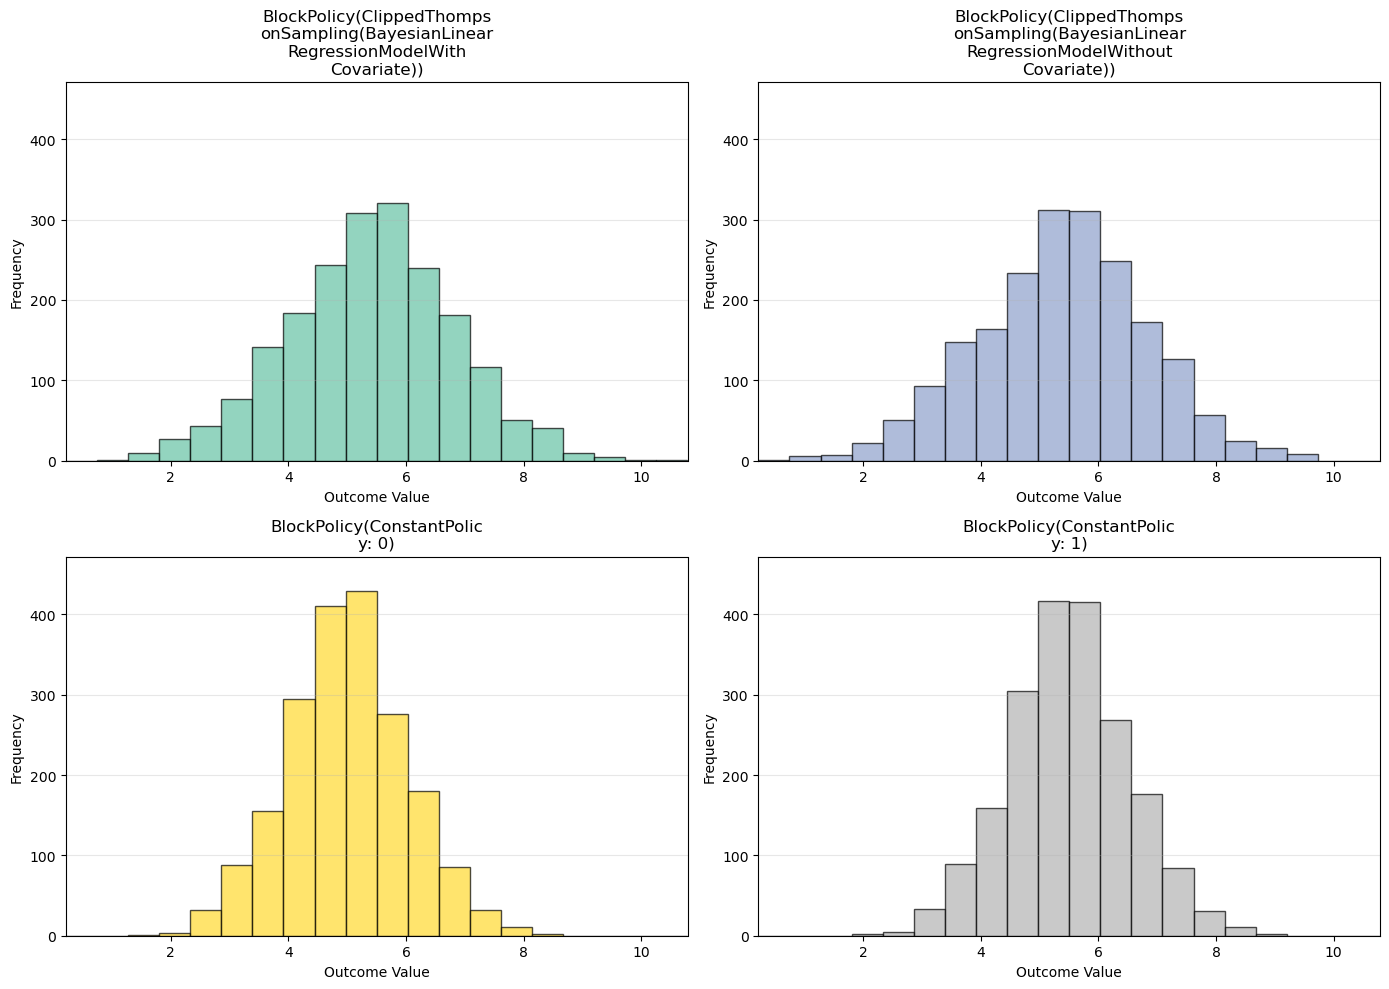

In [15]:
# Collect and plot outcomes as histograms with shared axes
if ENABLE_SIMULATION and 'calculated_series' in locals():
    print("=" * 80)
    print("OUTCOME DISTRIBUTION FOR EACH POLICY")
    print("=" * 80)
    
    policy_outcome_dict = {}
    
    # Collect outcomes for each policy
    for series in calculated_series:
        policy_name = str(series["configuration"]["policy"])
        outcomes = []
        
        for simulation in series["result"].simulations:
            for obs in simulation.history.observations:
                if "outcome" in obs.outcome:
                    outcomes.append(float(obs.outcome["outcome"]))
        
        if policy_name not in policy_outcome_dict:
            policy_outcome_dict[policy_name] = []
        policy_outcome_dict[policy_name].extend(outcomes)
    
    # Print statistics for each policy
    for policy_name, outcomes in sorted(policy_outcome_dict.items()):
        if len(outcomes) > 0:
            outcome_array = numpy.array(outcomes)
            print(f"\n{policy_name}")
            print("-" * 80)
            print(f"  Number of outcomes: {len(outcomes)}")
            print(f"  Mean outcome:       {numpy.mean(outcome_array):.4f}")
            print(f"  Median outcome:     {numpy.median(outcome_array):.4f}")
            print(f"  Std deviation:      {numpy.std(outcome_array):.4f}")
            print(f"  Min outcome:        {numpy.min(outcome_array):.4f}")
            print(f"  Max outcome:        {numpy.max(outcome_array):.4f}")
    
    # Plot individual histograms for each policy with shared axes
    outcome_data = [policy_outcome_dict[policy] for policy in sorted(policy_outcome_dict.keys())]
    policy_names = sorted(policy_outcome_dict.keys())
    
    # Determine shared axis limits
    all_outcomes = numpy.concatenate(outcome_data)
    x_min, x_max = all_outcomes.min(), all_outcomes.max()
    
    # Add padding to x-axis
    x_range = x_max - x_min
    x_min -= x_range * 0.05
    x_max += x_range * 0.05
    
    # Create subplots
    n_policies = len(policy_names)
    n_cols = 2
    n_rows = (n_policies + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
    if n_rows == 1 and n_cols == 1:
        axes = numpy.array([[axes]])
    elif n_rows == 1 or n_cols == 1:
        axes = axes.reshape(n_rows, n_cols)
    
    # Determine shared y-axis limit
    max_freq = 0
    for outcomes in outcome_data:
        counts, _ = numpy.histogram(outcomes, bins=20, range=(x_min, x_max))
        max_freq = max(max_freq, counts.max())
    
    # Plot each policy's histogram
    colors = plt.cm.Set2(numpy.linspace(0, 1, len(policy_names)))
    import textwrap
    for idx, (outcomes, policy_name, color) in enumerate(zip(outcome_data, policy_names, colors)):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]
        
        ax.hist(outcomes, bins=20, range=(x_min, x_max), color=color, edgecolor='black', alpha=0.7)
        ax.set_xlabel('Outcome Value')
        ax.set_ylabel('Frequency')
        wrapped_title = '\n'.join(textwrap.wrap(policy_name, width=25))
        ax.set_title(wrapped_title)
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(0, max_freq * 1.1)
        ax.grid(True, alpha=0.3, axis='y')
    
    # Hide unused subplots
    for idx in range(n_policies, n_rows * n_cols):
        row = idx // n_cols
        col = idx % n_cols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Simulation results not available. Run the simulation first.")


In [ ]:
df


,t,score,simulation,patient_id,model,policy,pooled,metric
0,0,-7.439045,SimulationData,0,SCM_Model_interaction_model,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
1,1,-13.113183,SimulationData,0,SCM_Model_interaction_model,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
2,2,-18.561137,SimulationData,0,SCM_Model_interaction_model,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
3,3,-22.810170,SimulationData,0,SCM_Model_interaction_model,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
4,4,-26.599146,SimulationData,0,SCM_Model_interaction_model,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
...,...,...,...,...,...,...,...,...
195,195,-1479.179617,SimulationData,9,SCM_Model_interaction_model,BlockPolicy(ClippedThompsonSampling(BayesianLi...,False,Cumulative Regret (outcome)
196,196,-1483.724024,SimulationData,9,SCM_Model_interaction_model,BlockPolicy(ClippedThompsonSampling(BayesianLi...,False,Cumulative Regret (outcome)
197,197,-1489.337525,SimulationData,9,SCM_Model_interaction_model,BlockPolicy(ClippedThompsonSampling(BayesianLi...,False,Cumulative Regret (outcome)
198,198,-1492.400613,SimulationData,9,SCM_Model_interaction_model,BlockPolicy(ClippedThompsonSampling(BayesianLi...,False,Cumulative Regret (outcome)


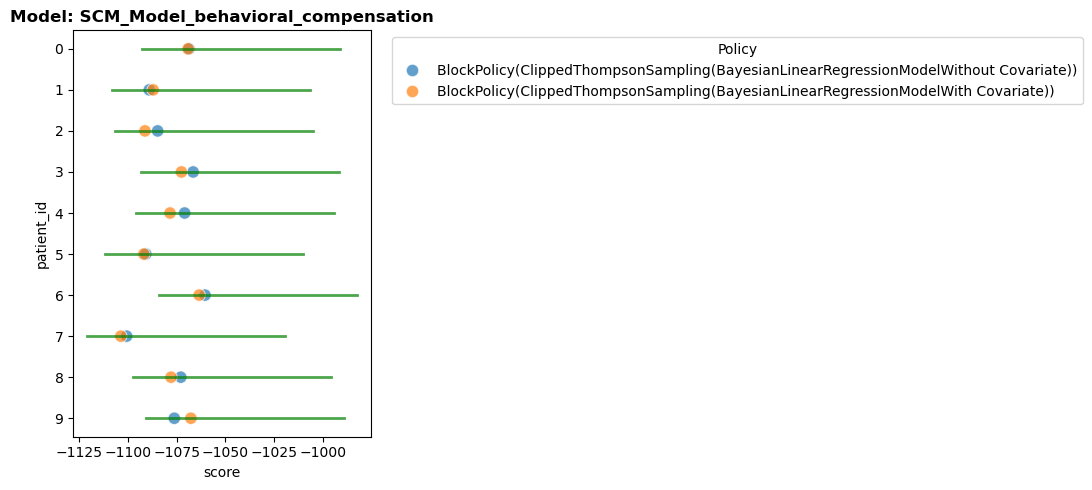

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

filtered_df = df[df["t"] == df["t"].max()]

models = filtered_df["model"].unique()
n_cols = 2
n_rows = (len(models) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
if n_rows == 1 and n_cols == 1:
    axes = numpy.array([[axes]])
elif n_rows == 1 or n_cols == 1:
    axes = axes.reshape(n_rows, n_cols)
axes = axes.flatten()

for idx, model in enumerate(models):
    model_df = filtered_df[filtered_df["model"] == model]
    
    # Scatterplot for other policies
    other_policies = model_df[~model_df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    sns.scatterplot(data=other_policies, x="score", y="patient_id", 
                    hue="policy", ax=axes[idx], s=80, alpha=0.7)
    
    # Add lines for min/max block policies
    block_df = model_df[model_df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    
    for patient_id in block_df["patient_id"].unique():
        patient_data = block_df[block_df["patient_id"] == patient_id]
        
        if len(patient_data) == 2:  # Both min and max exist
            min_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 0)"]["score"].values[0]
            max_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 1)"]["score"].values[0]
            
            # Determine color based on effect
            effect = min_score - max_score
            if effect > 1:
                color = 'green'  # Responder (positive effect)
            elif effect >= -1:
                color = 'grey'   # Neutral effect
            else:
                color = 'red'    # Negative effect
            
            # Draw line from min to max
            axes[idx].plot([min_score, max_score], [patient_id, patient_id], 
                          color=color, linewidth=2, alpha=0.7)
    
    axes[idx].set_title(f"Model: {model}", fontsize=12, fontweight='bold')
    axes[idx].legend(title="Policy", bbox_to_anchor=(1.05, 1), loc='upper left')

# Hide unused subplots
for idx in range(len(models), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()


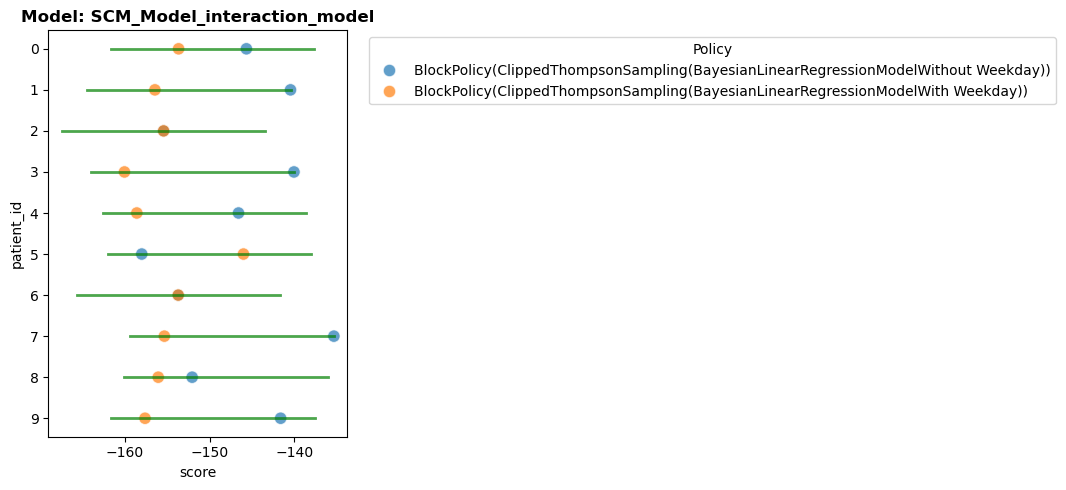

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

filtered_df = df[df["t"] == 20]

models = filtered_df["model"].unique()
n_cols = 2
n_rows = (len(models) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
if n_rows == 1 and n_cols == 1:
    axes = numpy.array([[axes]])
elif n_rows == 1 or n_cols == 1:
    axes = axes.reshape(n_rows, n_cols)
axes = axes.flatten()

for idx, model in enumerate(models):
    model_df = filtered_df[filtered_df["model"] == model]
    
    # Scatterplot for other policies
    other_policies = model_df[~model_df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    sns.scatterplot(data=other_policies, x="score", y="patient_id", 
                    hue="policy", ax=axes[idx], s=80, alpha=0.7)
    
    # Add lines for min/max block policies
    block_df = model_df[model_df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    
    for patient_id in block_df["patient_id"].unique():
        patient_data = block_df[block_df["patient_id"] == patient_id]
        
        if len(patient_data) == 2:  # Both min and max exist
            min_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 0)"]["score"].values[0]
            max_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 1)"]["score"].values[0]
            
            # Determine color based on effect
            effect = min_score - max_score
            if effect > 1:
                color = 'green'  # Responder (positive effect)
            elif effect >= -1:
                color = 'grey'   # Neutral effect
            else:
                color = 'red'    # Negative effect
            
            # Draw line from min to max
            axes[idx].plot([min_score, max_score], [patient_id, patient_id], 
                          color=color, linewidth=2, alpha=0.7)
    
    axes[idx].set_title(f"Model: {model}", fontsize=12, fontweight='bold')
    axes[idx].legend(title="Policy", bbox_to_anchor=(1.05, 1), loc='upper left')

# Hide unused subplots
for idx in range(len(models), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()
